# Canada's Wildfire Burden: Where It Falls, and Whether the Data Can Be Trusted

Scope: the approved fixed-reporting-agency series, as recorded in data/analysis_scope.json. Counts are reported records, not verified unique incidents. Agency is the reporting dimension, not geographic jurisdiction.

Source: Canadian Forest Service, Natural Resources Canada, Canadian National Fire Database - Agency Fire Data. Contains information licensed under the Open Government Licence - Canada. Source identity and checksum: data/source_versions.csv.

The opening answer is a placeholder and will be written last, after the detail pages are verified. Finding headings remain DRAFT: verify for the reviewer's wording. No Power BI assets are created here. The peak-year reported-area total is pending NFD reconciliation wherever displayed.


In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.analyse import query
from src.review_analysis import tables
review=tables()
review['decade_sensitivity']=pd.read_csv(ROOT/'data/processed/review_tables/decade_sensitivity.csv')
review['pooling_comparison']=pd.read_csv(ROOT/'data/processed/review_tables/pooling_comparison.csv')
def chart(name): display(Image(filename=str(ROOT/'images'/(name+'.png'))))


## The answer will be written after the detail is verified
I leave the executive synthesis pending and begin with the concentration evidence.

## DRAFT: verify: Within-agency top-three-percent area shares range from 59.46% to 99.56%
I compare the largest-record concentration with the mean and median. Cutoff record counts round upward and ties use the source-row key.

,reported_records,area_ha,mean_size_ha,median_size_ha
0,168276,8.398836e+07,499.110742,0.1


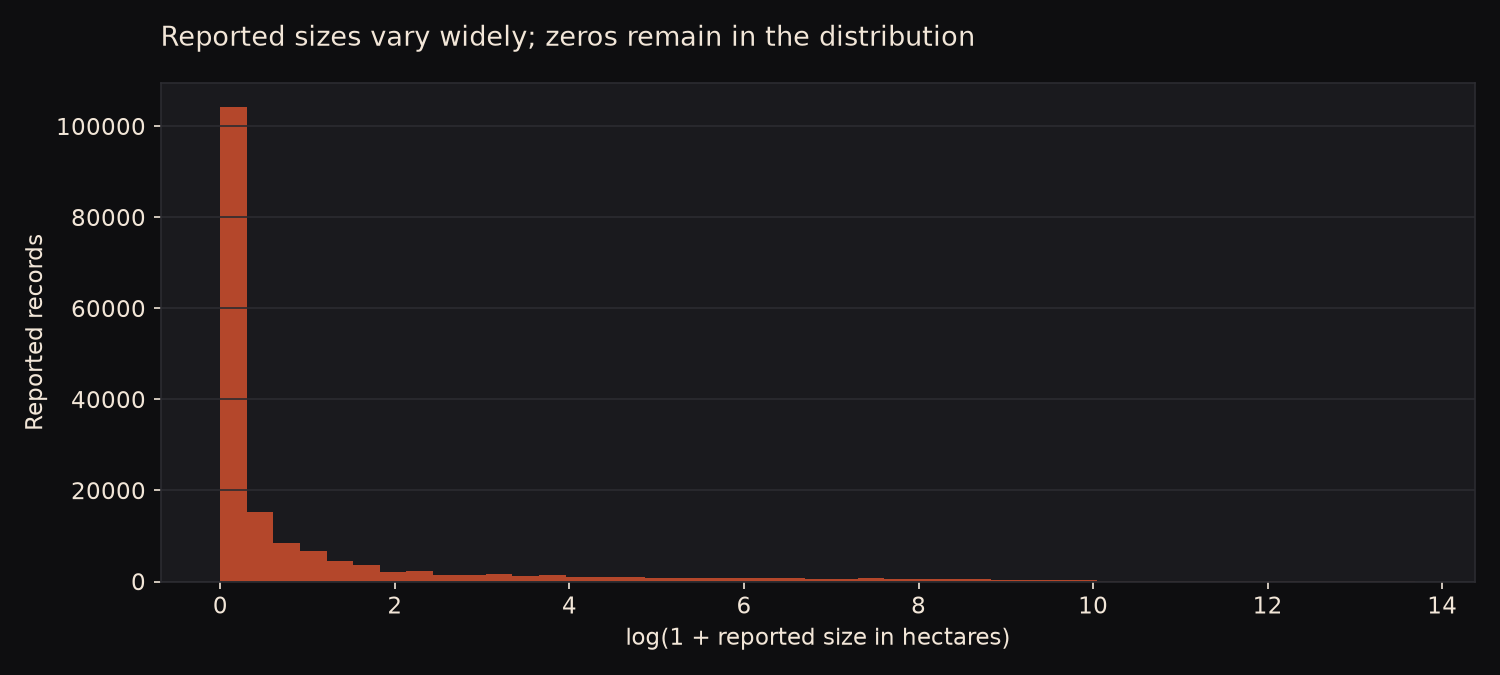

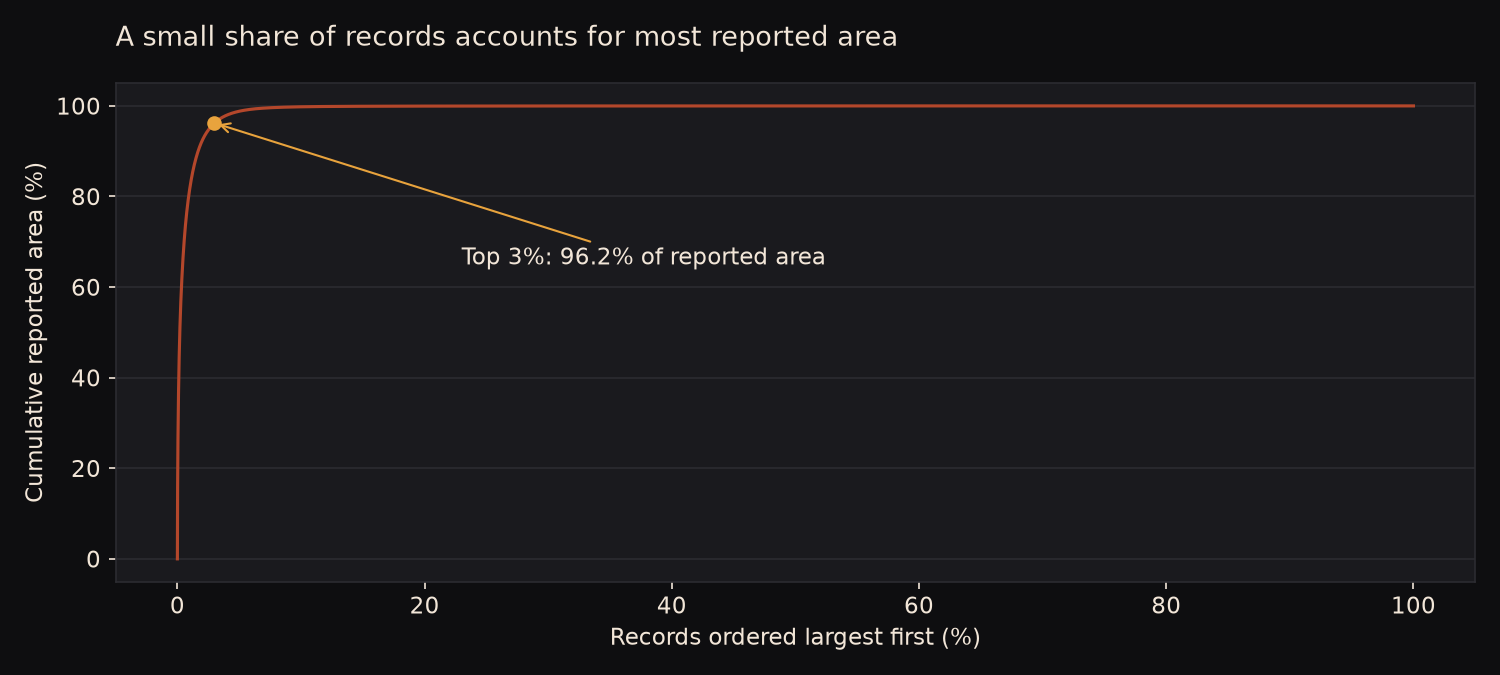

In [2]:
display(query('SELECT reported_records,area_ha,mean_size_ha,median_size_ha FROM vw_kpi_summary'))
chart('size_distribution')
chart('concentration')


### Takeaway
The largest three percent of selected records account for 96.21% of their reported area. The mean is 499.11 hectares and the median is 0.10 hectares. I would not present the mean as the typical recorded size.

## DRAFT: verify: Pooling uses a different cutoff from the 59.46% to 99.56% agency results
I recalculate the same cutoff within each reporting agency, using each agency's records and reported area as its denominator.

,reporting_agency,selected_records,area_share
0,AB,1065,0.995592
1,ALL,5049,0.962133
2,BC,1311,0.982854
3,MB,325,0.864508
4,NB,211,0.685472
5,NL,77,0.930413
6,NS,175,0.918283
7,NT,157,0.707036
8,ON,710,0.978353
9,PC,85,0.872132


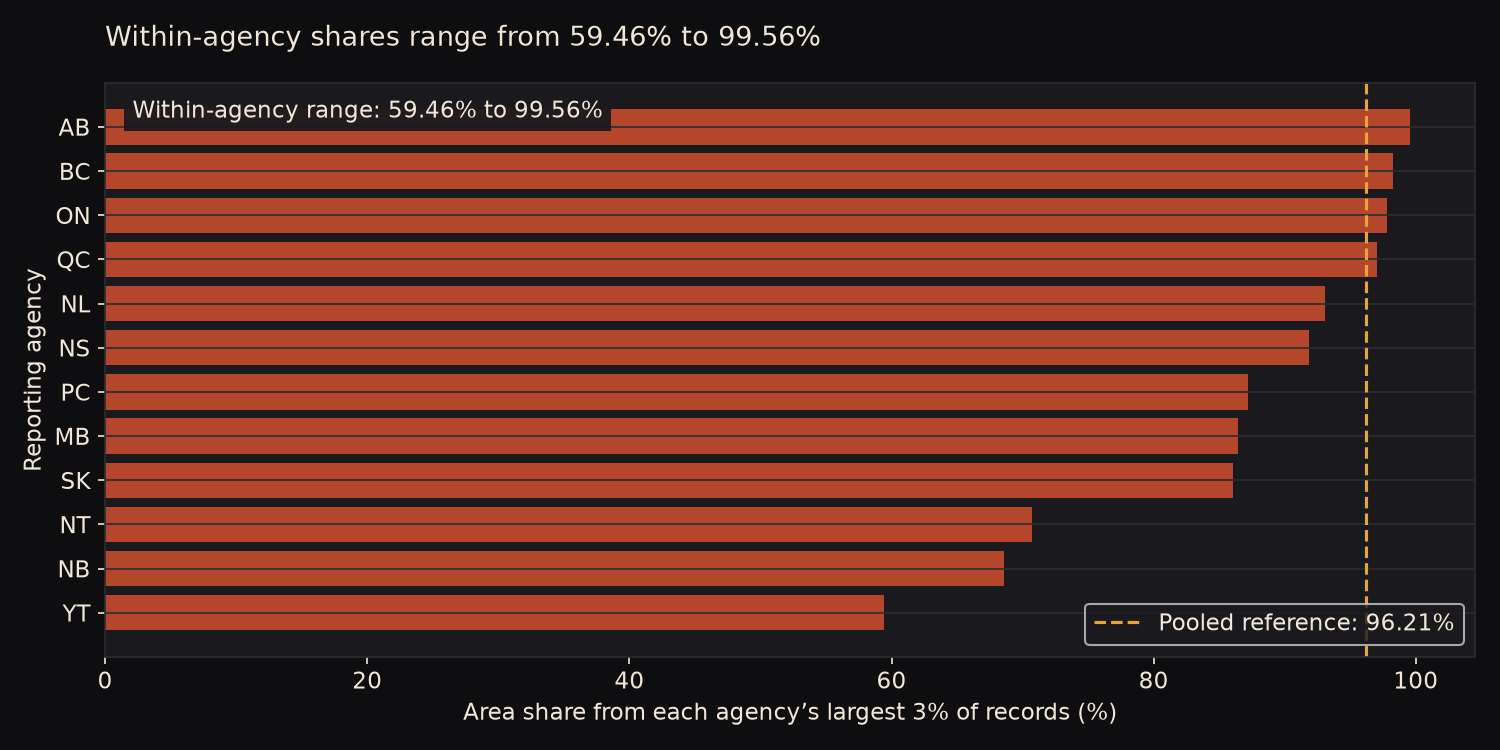

In [3]:
display(review['agency_top3'])
chart('agency_concentration')


In [4]:
display(review['pooling_comparison'])


,reporting_agency,agency_records,agency_area_ha,selected_records,area_share,pooled_top3_records,pooled_top3_area_ha,within_agency_top3_area_ha,agency_record_share_in_pooled_cutoff
0,AB,35475,8.466729e+06,1065,0.995592,370,8.238179e+06,8.429408e+06,0.010430
1,BC,43677,1.062113e+07,1311,0.982854,632,1.005857e+07,1.043901e+07,0.014470
2,MB,10828,8.256095e+06,325,0.864508,607,7.780118e+06,7.137460e+06,0.056058
3,NB,7032,1.407030e+04,211,0.685472,1,1.403000e+03,9.644800e+03,0.000142
4,NL,2540,4.067522e+05,77,0.930413,62,3.625460e+05,3.784473e+05,0.024409
5,NS,5825,5.141912e+04,175,0.918283,4,3.699069e+04,4.721732e+04,0.000687
6,NT,5222,1.668386e+07,157,0.707036,941,1.622891e+07,1.179609e+07,0.180199
7,ON,23662,4.342521e+06,710,0.978353,349,4.038692e+06,4.248517e+06,0.014749
8,PC,2815,3.419080e+06,85,0.872132,196,3.311413e+06,2.981890e+06,0.069627
9,QC,15636,9.753308e+06,470,0.970598,483,9.483535e+06,9.466538e+06,0.030890


### Why pooling changes the figure
Pooling does not average agency percentages: it selects the largest records across the entire selected cohort, reallocating slots between agencies whose fire-size distributions and record volumes differ. The area-weighted agency-specific selections capture 86.37% of all selected reported area, compared with 96.21% under the pooled cutoff; the allocation table shows how record fractions change. Pooling does not exceed every agency's share, and the independently rounded cutoffs select 5,054 records across agencies versus 5,049 pooled, so the rules differ slightly in count as well as membership.

### Takeaway
Within-agency top-three-percent area shares range from 59.46% in YT to 99.56% in AB, compared with 96.21% pooled. Concentration remains substantial, but the pooled percentage does not describe every agency. The table exposes that sensitivity instead of hiding it.

## DRAFT: verify: Recording differences limit a pooled comparison
I use the companion data-quality notebook to check exact small-size counts, near-value heaping, duplicate flags and coverage. These checks qualify the burden calculations rather than replacing them.

In [5]:
display(review['heaping'])


,reporting_agency,records,exactly_zero,exactly_001,exactly_01,near_001,near_01,exactly_zero_pct,exactly_001_pct,exactly_01_pct,near_001_pct,near_01_pct
0,AB,35475,0,16231,3844,16231,3844,0.000000,45.753347,10.835800,45.753347,10.835800
1,BC,43677,255,1896,3930,1896,3930,0.583831,4.340957,8.997871,4.340957,8.997871
2,MB,10828,154,0,1809,0,1809,1.422239,0.000000,16.706686,0.000000,16.706686
3,NB,7032,66,0,3440,0,3440,0.938567,0.000000,48.919226,0.000000,48.919226
4,NL,2540,1115,0,361,0,361,43.897638,0.000000,14.212598,0.000000,14.212598
5,NS,5825,929,689,623,838,721,15.948498,11.828326,10.695279,14.386266,12.377682
6,NT,5222,70,295,285,301,301,1.340483,5.649177,5.457679,5.764075,5.764075
7,ON,23662,2,0,490,0,10706,0.008452,0.000000,2.070831,0.000000,45.245541
8,PC,2815,41,448,533,448,533,1.456483,15.914742,18.934281,15.914742,18.934281
9,QC,15636,6159,0,2222,0,2222,39.389870,0.000000,14.210796,0.000000,14.210796


### Takeaway
Agency recording patterns and incomplete coverage affect comparability. I retain zeros in the primary median, flag unresolved identifiers and show small-size representation explicitly. NFD reconciliation remains pending.

## DRAFT: verify: The largest reported-area year changes the historical average
I compare annual totals, a full rolling window and a largest-year sensitivity without trend-significance or causal claims.

,year,reported_records,area_ha,yoy_area_change,five_year_mean_area,nfd_status
0,2000,5398,6.351868e+05,NaN,NaN,External reconciliation not completed
1,2001,7728,6.526082e+05,0.027427,NaN,External reconciliation not completed
2,2002,7845,2.761881e+06,3.232066,NaN,External reconciliation not completed
3,2003,8256,2.168393e+06,-0.214885,NaN,External reconciliation not completed
4,2004,6467,3.182984e+06,0.467900,1.880211e+06,External reconciliation not completed
5,2005,7437,1.686716e+06,-0.470083,2.090516e+06,External reconciliation not completed
6,2006,9711,2.100627e+06,0.245394,2.380120e+06,External reconciliation not completed
7,2007,6910,1.785425e+06,-0.150052,2.184829e+06,External reconciliation not completed
8,2008,6212,1.655625e+06,-0.072700,2.082275e+06,External reconciliation not completed
9,2009,7112,7.555638e+05,-0.543638,1.596791e+06,External reconciliation not completed


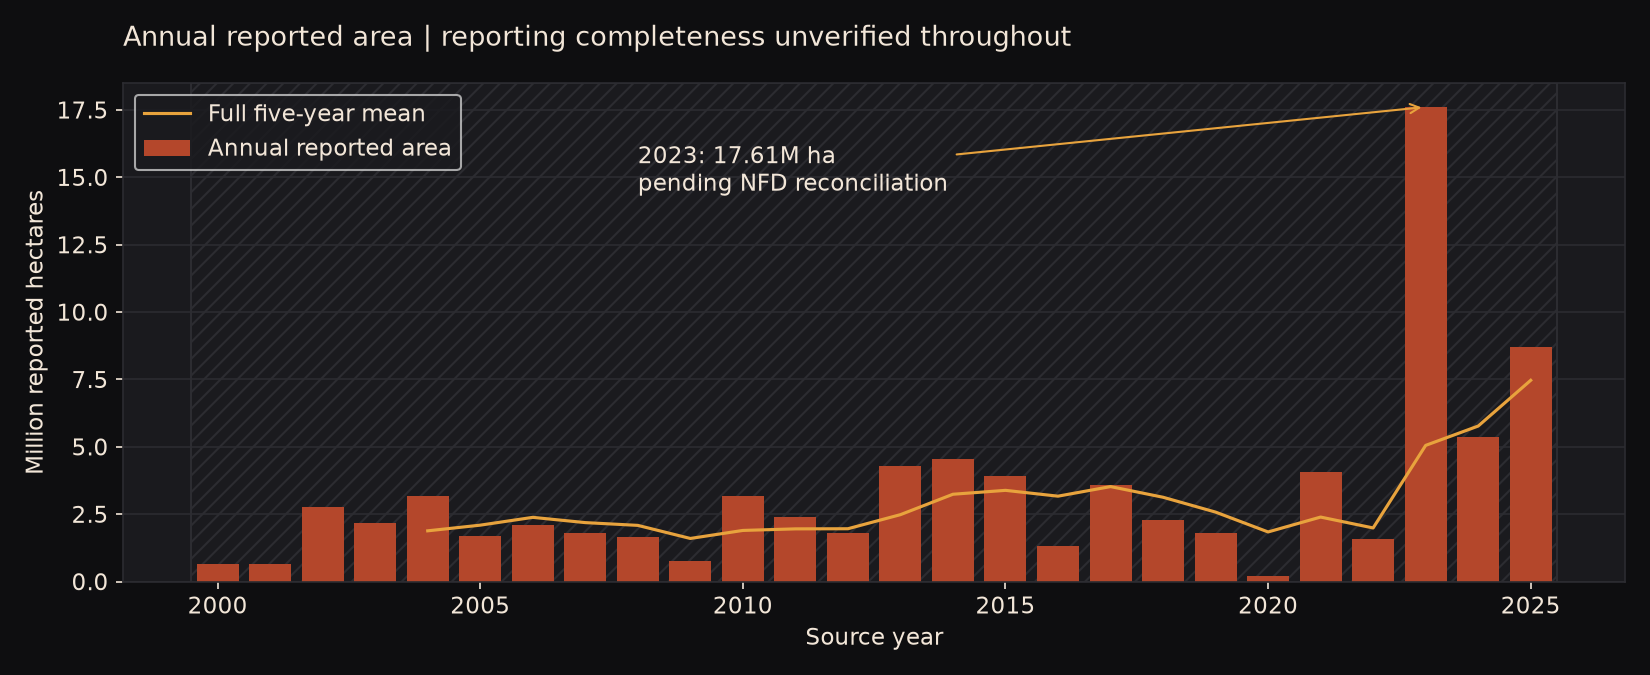

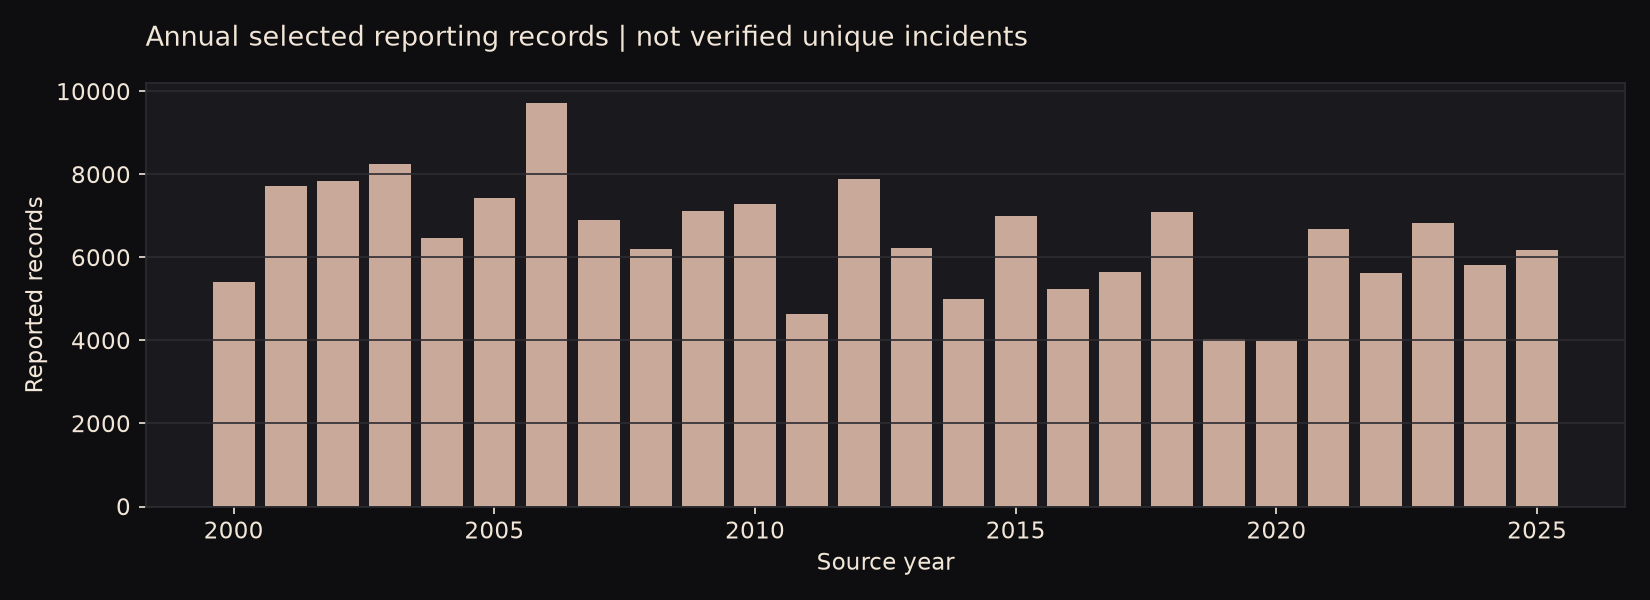

In [6]:
display(query("SELECT year,reported_records,area_ha,yoy_area_change,five_year_mean_area,CASE WHEN year=2023 THEN 'pending NFD reconciliation' ELSE 'External reconciliation not completed' END AS nfd_status FROM vw_annual_trend ORDER BY year"))
chart('annual_burden')
chart('annual_records')


In [7]:
display(query('SELECT scenario,years,reported_records,area_ha,mean_annual_area FROM vw_largest_year_sensitivity'))


,scenario,years,reported_records,area_ha,mean_annual_area
0,All selected years,26,168276,8.398836e+07,3.230322e+06
1,Largest area year removed,25,161451,6.638195e+07,2.655278e+06


### Takeaway
The largest selected total is 17.61 million reported hectares in 2023, pending NFD reconciliation. Removing that year lowers the annual mean from 3.23 to 2.66 million hectares. I treat that as sensitivity to an extreme year, not proof of a sustained trend.

## DRAFT: verify: Decade comparisons use unequal observed-year counts
I compare mean annual reported area and show each group's observed-year count rather than comparing unequal-duration totals.

In [8]:
display(review['decades'])


,decade,years_observed,reported_records,area_ha,mean_annual_area
0,2000,10,73076,1.738501e+07,1.738501e+06
1,2010,10,60066,2.906019e+07,2.906019e+06
2,2020,6,35134,3.754316e+07,6.257194e+06


In [9]:
display(review['decade_sensitivity'])


,period,excluded_year,years,total_area_ha,mean_annual_area_ha
0,2020–2025,NaN,6,3.754316e+07,6.257194e+06
1,2020–2025 excluding 2023,2023.0,5,1.993676e+07,3.987351e+06


### Sensitivity takeaway
The 2020–2025 mean annual reported area is 6.26 million hectares over six observed years. Excluding 2023, whose reported total is pending NFD reconciliation, leaves 3.99 million hectares per year over five years. This describes dependence on one year, not evidence of a trend.

### Takeaway
The 2000s group covers 10 observed years and averages 1.74 million reported hectares per year. The 2010s group covers 10 observed years and averages 2.91 million reported hectares per year. The 2020s group covers 6 observed years and averages 6.26 million reported hectares per year. The last group is a partial decade and includes the peak year, whose total is pending NFD reconciliation; these descriptive differences do not establish a reporting-adjusted trend.

## DRAFT: verify: Seasonal reporting patterns differ by agency
I use valid source months and preserve the unknown-month count separately.

,month_num,records,area_ha
0,-1,3418,1.716733e+06
1,1,312,1.449595e+04
2,2,271,6.075644e+04
3,3,1674,2.975361e+05
4,4,15009,4.848251e+05
5,5,29671,1.807771e+07
6,6,27582,2.973149e+07
7,7,42235,2.747954e+07
8,8,32012,5.536078e+06
9,9,10637,4.762890e+05


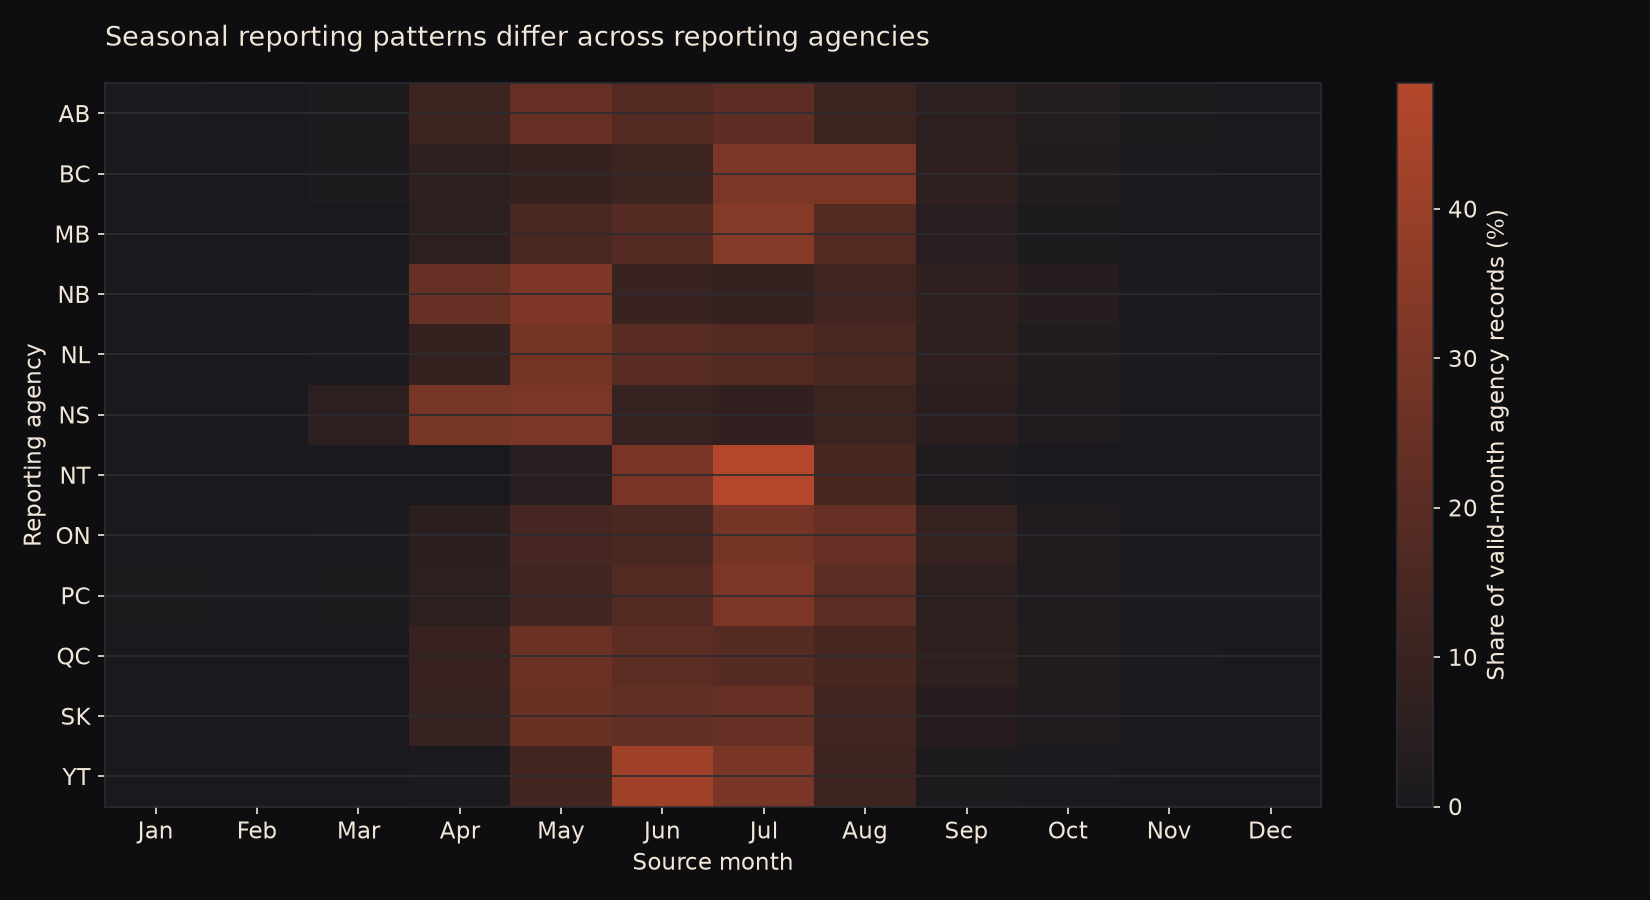

In [10]:
display(query('SELECT month_num,SUM(reported_records) AS records,SUM(area_ha) AS area_ha FROM vw_seasonality GROUP BY month_num ORDER BY month_num'))
chart('seasonality')


### Takeaway
July has the highest pooled valid-month count, 42,235. Another 3,418 selected records have no valid source month. Source month does not establish when all reported area burned.

## DRAFT: verify: Cause count shares differ from reported-area shares
I keep all cause classes, including Unknown, in both pooled denominators.

,cause_class,records,area_ha,count_share,area_share
0,Human,82858,6.585368e+06,0.492393,0.078408
1,Natural/lightning,77657,7.277785e+07,0.461486,0.866523
2,Unknown,7761,4.625143e+06,0.046121,0.055069


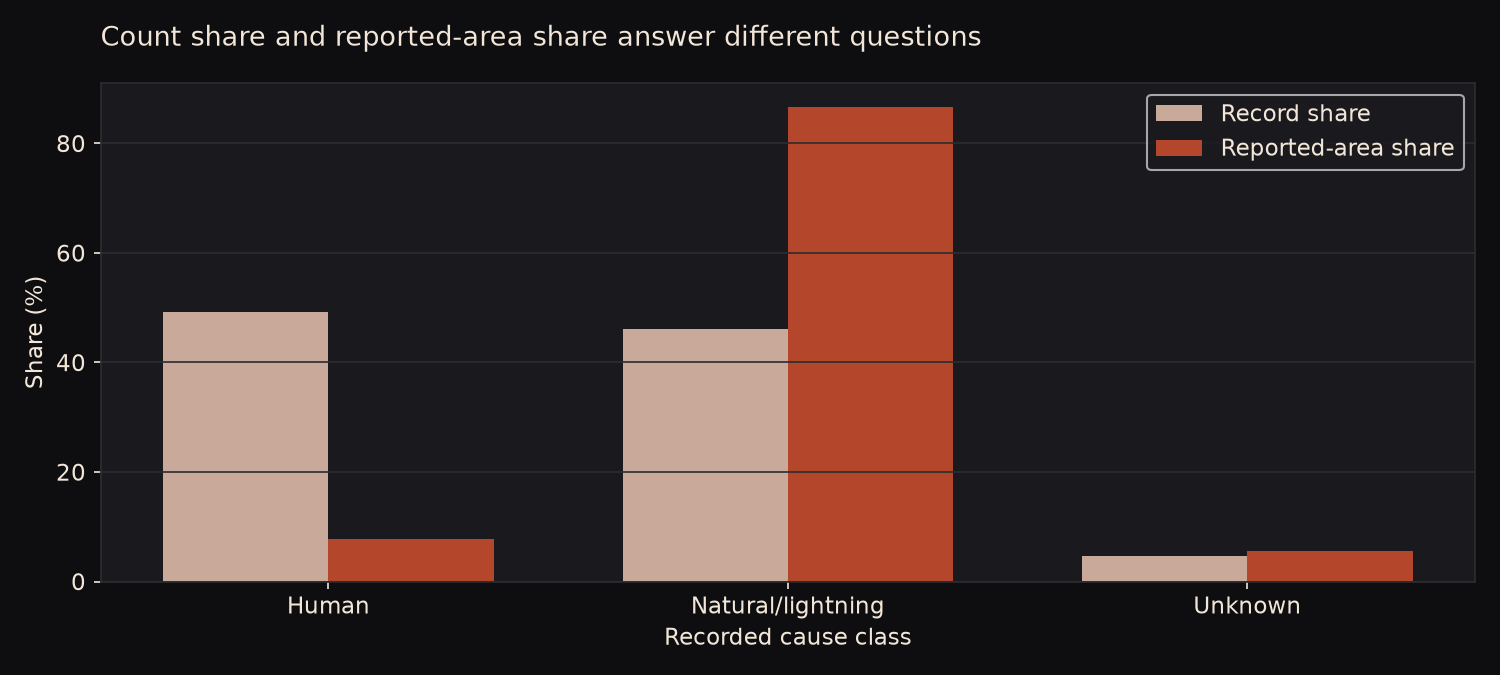

In [11]:
display(review['causes'])
chart('causes')


### Takeaway
Human represents 49.24% of selected records and 7.84% of reported area. Natural/lightning represents 46.15% of selected records and 86.65% of reported area. Unknown represents 4.61% of selected records and 5.51% of reported area; these are recorded classifications, not causal effects.

## DRAFT: verify: Cause-by-month segments provide a simpler pooled reporting view
I pool reporting agencies before calculating large-fire shares by cause and source month. I apply the minimum-record rule to the pooled segments, rather than averaging agency-level shares.

,cause_class,month_num,records,large_fire_records,large_fire_share,do_not_rank
0,Human,-1,82,3,0.036585,1
1,Human,1,250,1,0.004000,0
2,Human,2,217,2,0.009217,0
3,Human,3,1397,13,0.009306,0
4,Human,4,13948,145,0.010396,0
5,Human,5,24746,386,0.015598,0
6,Human,6,9996,111,0.011104,0
7,Human,7,10431,109,0.010450,0
8,Human,8,10318,64,0.006203,0
9,Human,9,6607,30,0.004541,0


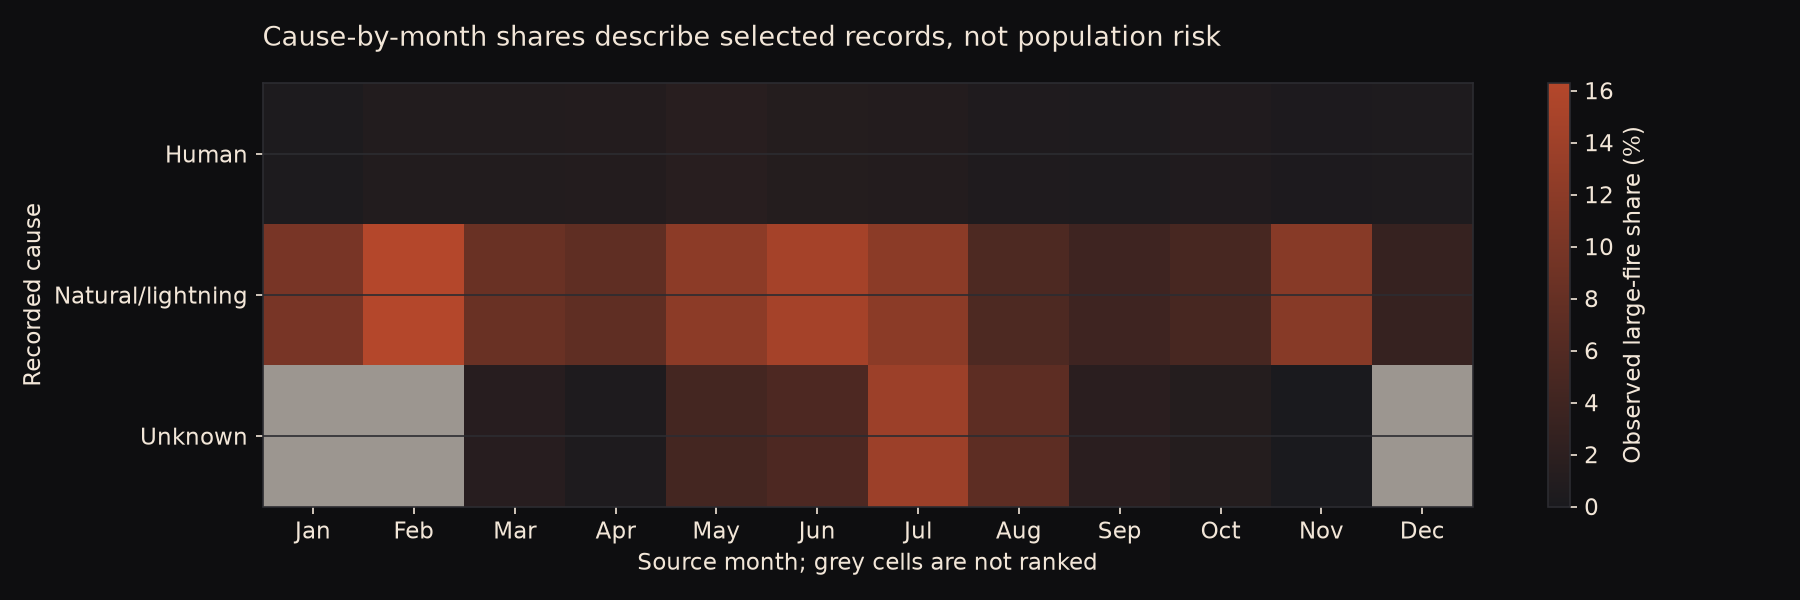

In [12]:
display(review['national_segments'])
chart('national_segments')


### Takeaway
These shares are conditional on selected reported records, not estimates of population risk. Unknown-month and below-minimum segments remain flagged rather than ranked. Agency-specific detail is retained only in the technical notebook section below.

## DRAFT: verify: Reporting-agency totals are not geographic provincial totals
I compare the selected agency submissions without geographic allocation or exposure-adjusted rates.

,reporting_agency,reported_records,area_ha,large_fire_share,unknown_cause_share
0,SK,12570,1.710130e+07,0.125537,0.004455
1,NT,5222,1.668386e+07,0.310034,0.022788
2,BC,43677,1.062113e+07,0.032878,0.008906
3,QC,15636,9.753308e+06,0.055257,0.001087
4,AB,35475,8.466729e+06,0.018830,0.032586
5,MB,10828,8.256095e+06,0.120151,0.264869
6,YT,2994,4.872098e+06,0.287575,0.163327
7,ON,23662,4.342521e+06,0.032795,0.019694
8,PC,2815,3.419080e+06,0.124689,0.049734
9,NL,2540,4.067522e+05,0.046457,0.014961


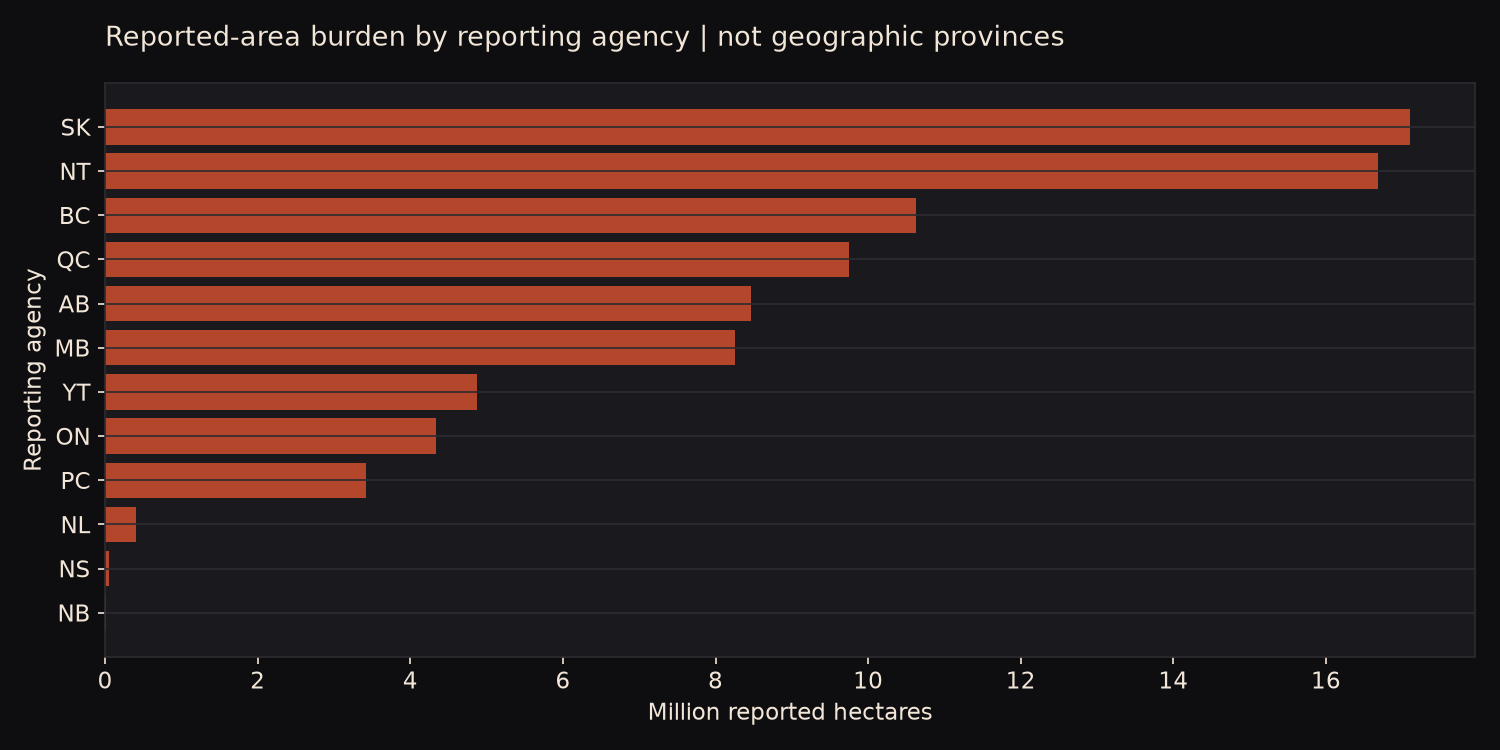

In [13]:
display(query('SELECT reporting_agency,reported_records,area_ha,large_fire_share,unknown_cause_share FROM vw_agency ORDER BY area_ha DESC'))
chart('agency_burden')


### Takeaway
SK has the largest selected reporting-agency area sum, 17.10 million reported hectares. Reporting scope and coverage differ, and Parks Canada remains its own reporting agency. I do not interpret the ordering as performance or public risk.

## DRAFT: verify: NT response classification has different record and area shares
I restrict this view to selected NT records and show FUL, MOD, MON and Unknown. Every record-share denominator is all selected NT records; every area-share denominator is all reported area in that same cohort, including Unknown.

,response_classification,records,area_ha,record_share,area_share,record_denominator,area_denominator_ha
0,FUL,1883,1.283676e+06,0.360590,0.076941,5222,1.668386e+07
1,MOD,287,4.808438e+06,0.054960,0.288209,5222,1.668386e+07
2,MON,2967,1.021739e+07,0.568173,0.612411,5222,1.668386e+07
3,Unknown,85,3.743612e+05,0.016277,0.022439,5222,1.668386e+07


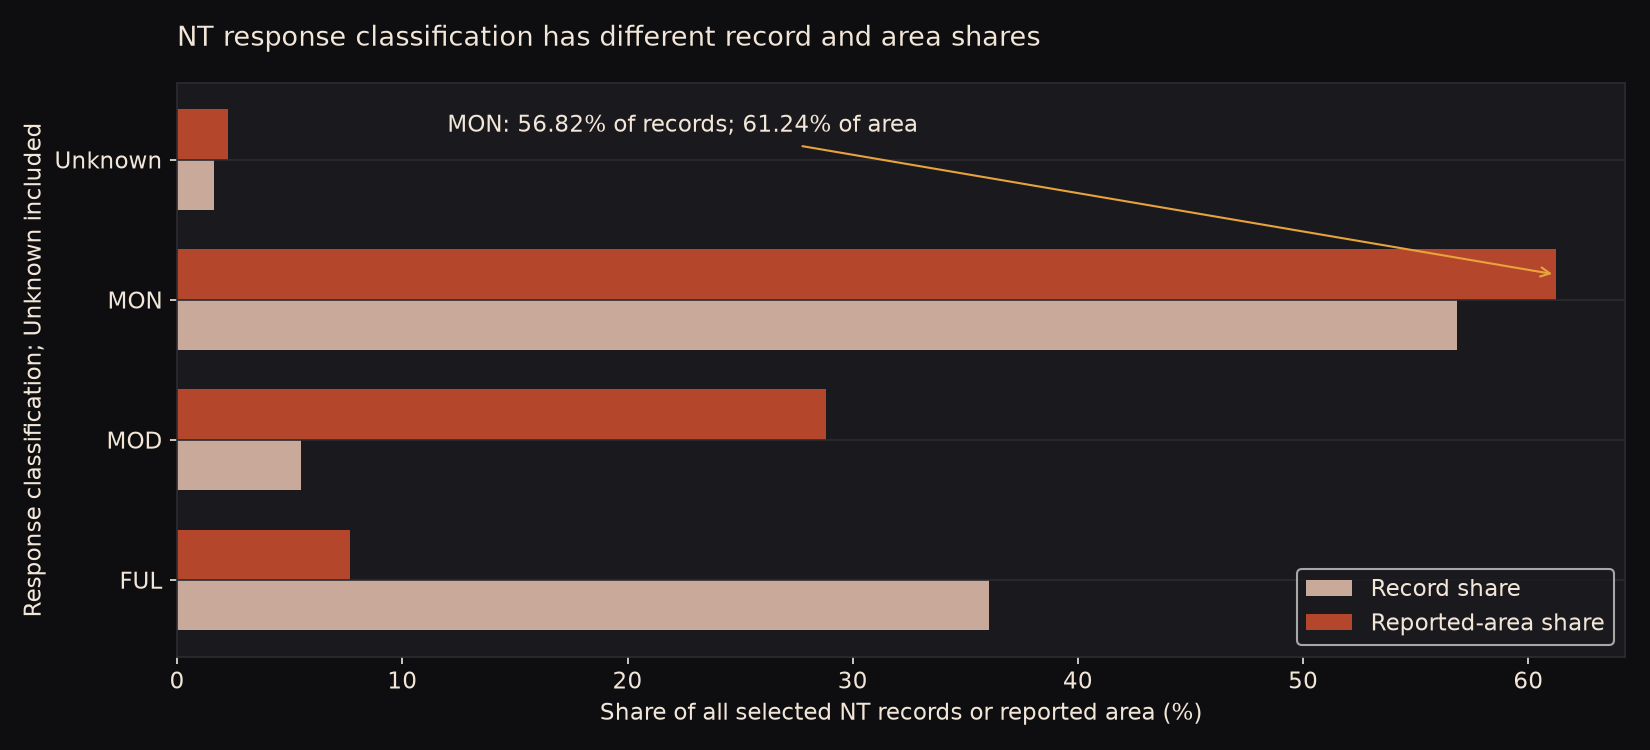

In [14]:
display(review['nt_response'])
chart('nt_response_classification')


### Takeaway
FUL represents 36.06% of NT selected records and 7.69% of NT reported area; MOD represents 5.50% of NT selected records and 28.82% of NT reported area; MON represents 56.82% of NT selected records and 61.24% of NT reported area; Unknown represents 1.63% of NT selected records and 2.24% of NT reported area. These classes do not establish a suppression effect.

## Technical notebook detail: full agency-by-cause-by-month segments
This full table stays in the notebook only and will not be used as the reporting or dashboard segment view.

In [15]:
full_segments=query('SELECT reporting_agency,cause_class,month_num,reported_records,large_fire_records,large_fire_share,do_not_rank FROM vw_segments ORDER BY reporting_agency,cause_class,month_num')
with pd.option_context('display.max_rows',None):
    display(full_segments)

,reporting_agency,cause_class,month_num,reported_records,large_fire_records,large_fire_share,do_not_rank
0,AB,Human,1,155,0,0.000000,0
1,AB,Human,2,117,1,0.008547,0
2,AB,Human,3,477,1,0.002096,0
3,AB,Human,4,3778,21,0.005558,0
4,AB,Human,5,7094,62,0.008740,0
5,AB,Human,6,1925,5,0.002597,0
6,AB,Human,7,2156,3,0.001391,0
7,AB,Human,8,2088,3,0.001437,0
8,AB,Human,9,1700,6,0.003529,0
9,AB,Human,10,1125,3,0.002667,0


### Takeaway
The full table preserves traceability for a technical review. I will use the pooled cause-by-month version for reporting and continue to flag small or unknown-month segments. Neither table is a forecast.